# Projeto Final: Classificação de Cães e Gatos com CNN
Integrantes: (Beatriz Cavalcante, Flávia Melo e Renan Cunha)

## Etapa 1: Definição do problema
Objetivo: dada uma foto colorida, classificar se é um cão ou um gato (classificação binária de imagens).

Relevância: reconhecimento de animais por imagem é usado em abrigos, apps de pets, câmeras de monitoramento e organização de fotos.

Modelo: CNN, adequada para imagens porque aprende padrões visuais (bordas, texturas, formas) sem precisar que a gente os defina.

In [ ]:
# ============================================================
#  IMPORTAR AS BIBLIOTECAS
# ============================================================

import os
import zipfile
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.models import load_model

In [ ]:
# ============================================================
#  UPLOAD DO ARQUIVO ZIP
# ============================================================
# Ao executar esta parte no Google Colab, clique em
# "Escolher arquivos" e selecione o arquivo .zip do dataset.

uploaded = files.upload()

# Pega automaticamente o nome do arquivo enviado.
zip_path = list(uploaded.keys())[0]

print("Arquivo enviado:", zip_path)

Saving archive (3).zip to archive (3).zip
Arquivo enviado: archive (3).zip


In [ ]:
# DESCOMPACTAR O DATASET
pasta_extraida = "/content/dataset_original"

# Apaga a pasta antiga, caso o código seja executado novamente.
if os.path.exists(pasta_extraida):
    shutil.rmtree(pasta_extraida)

os.makedirs(pasta_extraida)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(pasta_extraida)

print("Dataset descompactado!")
print("Conteúdo inicial:", os.listdir(pasta_extraida)[:10])


Dataset descompactado!
Conteúdo inicial: ['train_transformed']


In [ ]:
# ============================================================
# LOCALIZAR AS IMAGENS DE CÃES E GATOS
# ============================================================
# O código procura arquivos com nomes semelhantes a:
# cat.0.jpg (originalmente com ponto, mas o dataset atual tem 'cat0.jpg')
# dog.0.jpg (originalmente com ponto, mas o dataset atual tem 'dog0.jpg')
#
# A busca é feita também dentro de subpastas, caso o ZIP
# tenha criado uma pasta chamada "train".

imagens_gatos = []
imagens_caes = []

for raiz, pastas, arquivos in os.walk(pasta_extraida):
    for arquivo in arquivos:

        nome = arquivo.lower()

        if nome.startswith("cat") and nome.endswith((".jpg", ".jpeg", ".png")):
            imagens_gatos.append(os.path.join(raiz, arquivo))

        elif nome.startswith("dog") and nome.endswith((".jpg", ".jpeg", ".png")):
            imagens_caes.append(os.path.join(raiz, arquivo))

print("Total de gatos encontrados:", len(imagens_gatos))
print("Total de cachorros encontrados:", len(imagens_caes))

Total de gatos encontrados: 1000
Total de cachorros encontrados: 1000


In [ ]:
# ============================================================
#  EMBARALHAR AS IMAGENS
# ============================================================
# Usamos uma semente fixa para que a divisão possa ser
# reproduzida novamente.

random.seed(123)

random.shuffle(imagens_gatos)
random.shuffle(imagens_caes)


In [ ]:
# ============================================================
#  CRIAR TREINO, VALIDAÇÃO E TESTE
# ============================================================
# Divisão utilizada:
#
# 70% -> Treino
# 15% -> Validação
# 15% -> Teste
#
# A separação é feita individualmente para cada classe.
# Assim mantemos gatos e cachorros distribuídos entre
# os três conjuntos.

def dividir_dados(lista):

    total = len(lista)

    fim_treino = int(total * 0.70)
    fim_validacao = int(total * 0.85)

    treino = lista[:fim_treino]
    validacao = lista[fim_treino:fim_validacao]
    teste = lista[fim_validacao:]

    return treino, validacao, teste


gatos_treino, gatos_val, gatos_teste = dividir_dados(imagens_gatos)
caes_treino, caes_val, caes_teste = dividir_dados(imagens_caes)


In [ ]:
# ============================================================
# CRIAR A ESTRUTURA DE PASTAS
# ============================================================
#
# dataset_final/
#
# ├── train/
# │   ├── cats/
# │   └── dogs/
# │
# ├── validation/
# │   ├── cats/
# │   └── dogs/
# │
# └── test/
#     ├── cats/
#     └── dogs/

dataset_final = "/content/dataset_final"

if os.path.exists(dataset_final):
    shutil.rmtree(dataset_final)

pastas = [
    "train/cats",
    "train/dogs",
    "validation/cats",
    "validation/dogs",
    "test/cats",
    "test/dogs"
]

for pasta in pastas:
    os.makedirs(os.path.join(dataset_final, pasta), exist_ok=True)


In [ ]:
# ============================================================
# COPIAR AS IMAGENS PARA AS PASTAS
# ============================================================

def copiar_imagens(lista, destino):

    for caminho in lista:
        shutil.copy2(caminho, destino)


copiar_imagens(gatos_treino, dataset_final + "/train/cats")
copiar_imagens(caes_treino, dataset_final + "/train/dogs")

copiar_imagens(gatos_val, dataset_final + "/validation/cats")
copiar_imagens(caes_val, dataset_final + "/validation/dogs")

copiar_imagens(gatos_teste, dataset_final + "/test/cats")
copiar_imagens(caes_teste, dataset_final + "/test/dogs")

print("Separação concluída!")


Separação concluída!


In [ ]:
# ============================================================
# CONFERIR A QUANTIDADE DE IMAGENS
# ============================================================

print("\nTREINO")
print("Gatos:", len(os.listdir(dataset_final + "/train/cats")))
print("Cachorros:", len(os.listdir(dataset_final + "/train/dogs")))

print("\nVALIDAÇÃO")
print("Gatos:", len(os.listdir(dataset_final + "/validation/cats")))
print("Cachorros:", len(os.listdir(dataset_final + "/validation/dogs")))

print("\nTESTE")
print("Gatos:", len(os.listdir(dataset_final + "/test/cats")))
print("Cachorros:", len(os.listdir(dataset_final + "/test/dogs")))



TREINO
Gatos: 700
Cachorros: 700

VALIDAÇÃO
Gatos: 150
Cachorros: 150

TESTE
Gatos: 150
Cachorros: 150


In [ ]:
# ============================================================
#  CARREGAR OS DATASETS COM O KERAS
# ============================================================
# Todas as imagens serão redimensionadas para 150 x 150.
# batch_size = 32 significa que o modelo trabalha com
# grupos de 32 imagens por vez.

img_size = (150, 150)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_final + "/train",
    image_size=img_size,
    batch_size=batch_size,
    shuffle=True,
    seed=123
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_final + "/validation",
    image_size=img_size,
    batch_size=batch_size,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_final + "/test",
    image_size=img_size,
    batch_size=batch_size,
    shuffle=False
)

class_names = train_ds.class_names

print("\nClasses encontradas:", class_names)


Found 1400 files belonging to 2 classes.
Found 300 files belonging to 2 classes.
Found 300 files belonging to 2 classes.

Classes encontradas: ['cats', 'dogs']


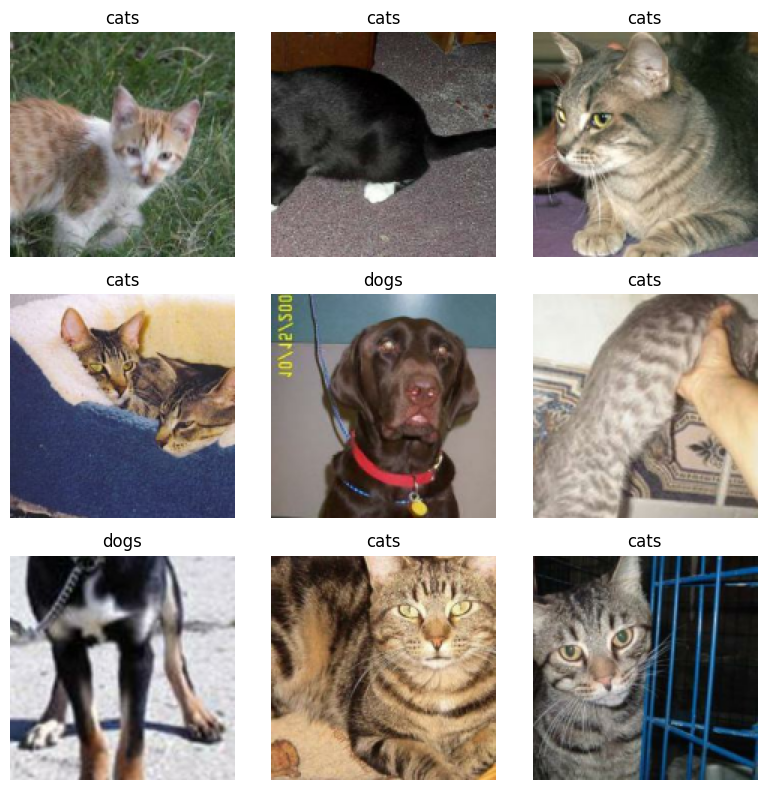

In [ ]:
# ============================================================
# VISUALIZAR ALGUMAS IMAGENS
# ============================================================

plt.figure(figsize=(8, 8))

for imagens, labels in train_ds.take(1):

    for i in range(9):

        plt.subplot(3, 3, i + 1)

        plt.imshow(imagens[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CRIAR A REDE NEURAL CONVOLUCIONAL (CNN)
# ============================================================
#
# Rescaling:
# transforma pixels de 0-255 para valores entre 0-1.
#
# Conv2D:
# procura características nas imagens.
#
# MaxPooling2D:
# reduz o tamanho das informações.
#
# Dropout:
# desliga aleatoriamente uma porcentagem dos neurônios
# para evitar o overfitting.
#
# Flatten:
# transforma os mapas de características em um vetor.
#
# Dense:
# realiza a classificação.
#
# Sigmoid:
# usada porque temos duas classes: gatos e cachorros.

model = models.Sequential([

    layers.Input(shape=(150, 150, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.3), # Adicionado Dropout

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.3), # Adicionado Dropout

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.3), # Adicionado Dropout

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3), # Adicionado Dropout antes da camada densa final

    layers.Dense(1, activation="sigmoid")
])

In [ ]:
# ============================================================
# COMPILAR O MODELO
# ============================================================
#
# Adam:
# ajusta os pesos da rede.
#
# binary_crossentropy:
# mede o erro em uma classificação com duas classes.
#
# accuracy:
# mede a porcentagem de acertos.

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
# ============================================================
# MOSTRAR A ESTRUTURA DA CNN
# ============================================================

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ============================================================
# CRIAR O CHECKPOINT
# ============================================================
# O checkpoint salva o modelo que apresentar o MENOR
# erro de validação (val_loss).

checkpoint = ModelCheckpoint(
    "/content/melhor_modelo.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)


In [ ]:
# ============================================================
# TREINAR A CNN
# ============================================================
# Uma época significa uma passagem completa pelos dados
# de treinamento.
#
# O conjunto de teste NÃO é utilizado nesta etapa.

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[checkpoint]
)

Epoch 1/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - accuracy: 0.4922 - loss: 0.9300
Epoch 1: val_loss improved from None to 0.69305, saving model to /content/melhor_modelo.keras

Epoch 1: finished saving model to /content/melhor_modelo.keras
44/44 ━━━━━━━━━━━━━━━━━━━━ 25s 294ms/step - accuracy: 0.4929 - loss: 0.7697 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/10
43/44 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5294 - loss: 0.6899
Epoch 2: val_loss improved from 0.69305 to 0.68993, saving model to /content/melhor_modelo.keras

Epoch 2: finished saving model to /content/melhor_modelo.keras
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.5236 - loss: 0.6874 - val_accuracy: 0.5100 - val_loss: 0.6899
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5462 - loss: 0.6906
Epoch 3: val_loss improved from 0.68993 to 0.68607, saving model to /content/melhor_modelo.keras

Epoch 3: finished saving model to /content/melhor_modelo.keras
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 

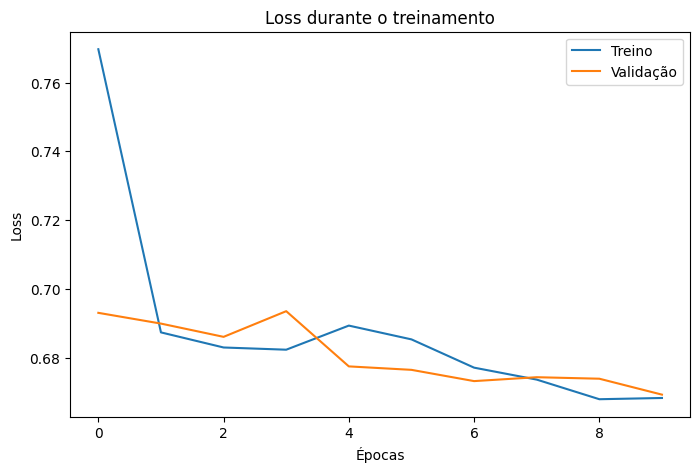

In [ ]:
# ============================================================
# ETAPA 17 — GRÁFICO DO LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Treino")
plt.plot(history.history["val_loss"], label="Validação")

plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.title("Loss durante o treinamento")
plt.legend()

plt.show()

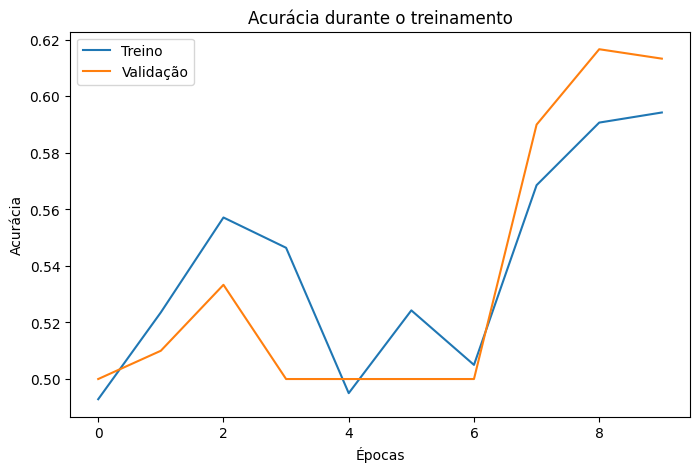

In [ ]:
# ============================================================
# GRÁFICO DA ACURÁCIA
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Treino")
plt.plot(history.history["val_accuracy"], label="Validação")

plt.xlabel("Épocas")
plt.ylabel("Acurácia")
plt.title("Acurácia durante o treinamento")
plt.legend()

plt.show()

In [ ]:
# ============================================================
# IDENTIFICAR A MELHOR ÉPOCA
# ============================================================

melhor_epoca = np.argmin(history.history["val_loss"]) + 1
melhor_val_loss = np.min(history.history["val_loss"])

print("Melhor época:", melhor_epoca)
print("Menor val_loss:", melhor_val_loss)

Melhor época: 10
Menor val_loss: 0.6692742705345154


In [ ]:
# ============================================================
# CARREGAR O MELHOR MODELO
# ============================================================

melhor_modelo = load_model("/content/melhor_modelo.keras")

print("Melhor modelo carregado!")


Melhor modelo carregado!


In [ ]:
# ============================================================
# AVALIAÇÃO FINAL COM O CONJUNTO DE TESTE
# ============================================================
# Somente agora usamos o conjunto de teste.
#
# Essas imagens não foram utilizadas para treinar o modelo
# nem para escolher a melhor época.

test_loss, test_accuracy = melhor_modelo.evaluate(test_ds)

print("\nRESULTADO FINAL")
print("Loss no teste:", test_loss)
print("Acurácia no teste:", test_accuracy)
print("Acurácia no teste (%):", test_accuracy * 100)


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 0.5167 - loss: 0.6900

RESULTADO FINAL
Loss no teste: 0.6900379061698914
Acurácia no teste: 0.5166666507720947
Acurácia no teste (%): 51.66666507720947


In [ ]:
# ============================================================
# FAZER PREVISÕES NO CONJUNTO DE TESTE
# ============================================================
# A sigmoid produz valores entre 0 e 1.
#
# Valor < 0.5 -> classe 0
# Valor >= 0.5 -> classe 1

imagens_lista = []
reais_lista = []
previstos_lista = []
probabilidades_lista = []

for imagens, labels in test_ds:

    probabilidades = melhor_modelo.predict(imagens, verbose=0).flatten()

    previsoes = (probabilidades >= 0.5).astype("int32")

    imagens_lista.extend(imagens.numpy())
    reais_lista.extend(labels.numpy())
    previstos_lista.extend(previsoes)
    probabilidades_lista.extend(probabilidades)

print("Previsões realizadas!")


Previsões realizadas!


In [ ]:
# ============================================================
# LOCALIZAR OS ACERTOS E OS ERROS
# ============================================================

acertos = []
erros = []

for i in range(len(reais_lista)):

    if reais_lista[i] == previstos_lista[i]:
        acertos.append(i)

    else:
        erros.append(i)

print("Quantidade de acertos:", len(acertos))
print("Quantidade de erros:", len(erros))

Quantidade de acertos: 155
Quantidade de erros: 145


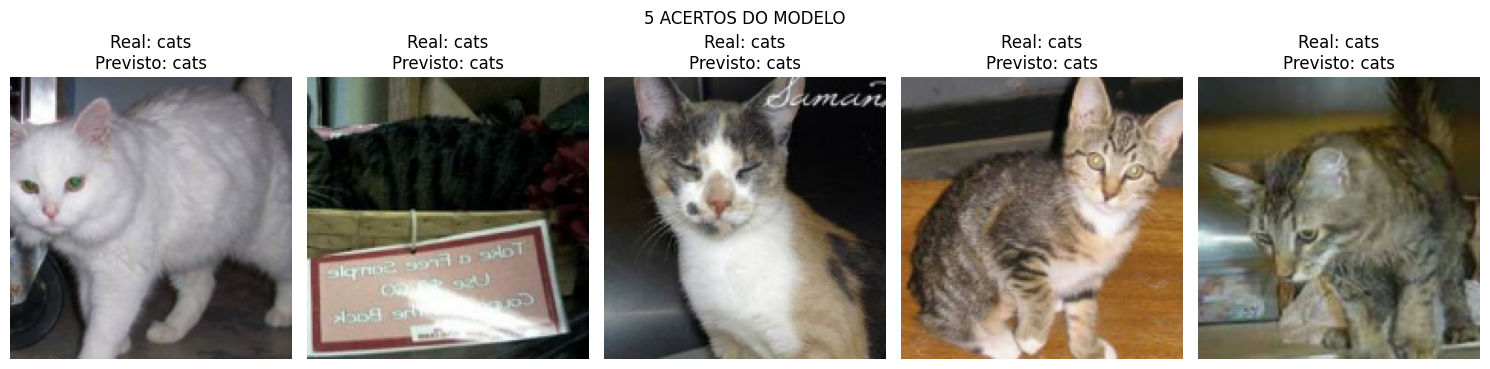

In [ ]:
# ============================================================
# MOSTRAR 5 ACERTOS
# ============================================================

# Garantir que a lista de acertos exista na memória
if 'acertos' not in globals():
    print("Criando as listas de acertos e erros automaticamente...")
    acertos = []
    erros = []
    for i in range(len(reais_lista)):
        if reais_lista[i] == previstos_lista[i]:
            acertos.append(i)
        else:
            erros.append(i)
    globals()['acertos'] = acertos
    globals()['erros'] = erros

plt.figure(figsize=(15, 4))

for posicao, i in enumerate(acertos[:5]):

    plt.subplot(1, 5, posicao + 1)

    plt.imshow(imagens_lista[i].astype("uint8"))

    real = class_names[int(reais_lista[i])]
    previsto = class_names[int(previstos_lista[i])]

    plt.title(
        f"Real: {real}\n"
        f"Previsto: {previsto}"
    )

    plt.axis("off")

plt.suptitle("5 ACERTOS DO MODELO")
plt.tight_layout()
plt.show()

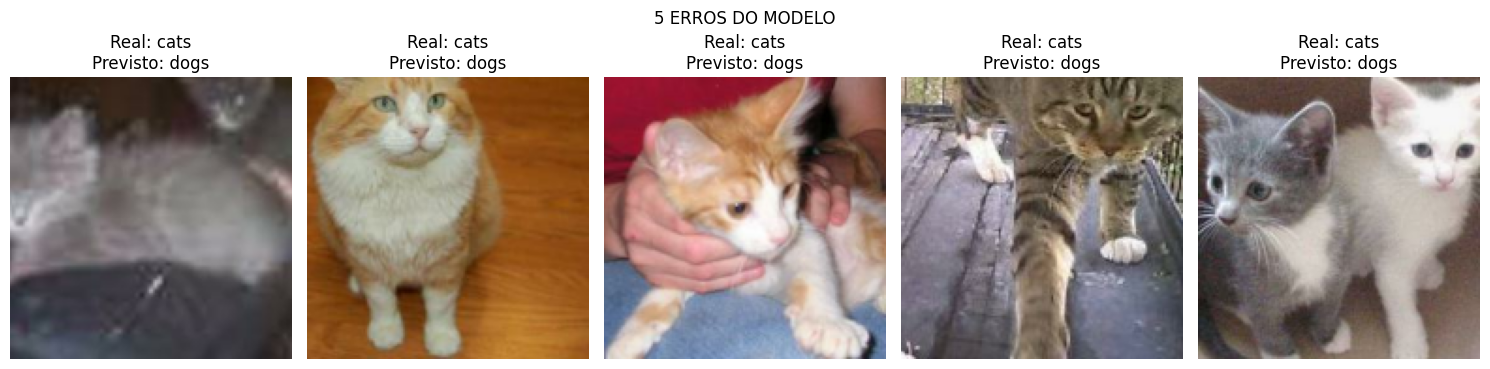

In [ ]:
# ============================================================
# MOSTRAR 5 ERROS
# ============================================================

if len(erros) > 0:

    quantidade = min(5, len(erros))

    plt.figure(figsize=(15, 4))

    for posicao, i in enumerate(erros[:quantidade]):

        plt.subplot(1, quantidade, posicao + 1)

        plt.imshow(imagens_lista[i].astype("uint8"))

        real = class_names[int(reais_lista[i])]
        previsto = class_names[int(previstos_lista[i])]

        plt.title(
            f"Real: {real}\n"
            f"Previsto: {previsto}"
        )

        plt.axis("off")

    plt.suptitle("5 ERROS DO MODELO")
    plt.tight_layout()
    plt.show()

else:
    print("O modelo não apresentou erros no conjunto de teste.")


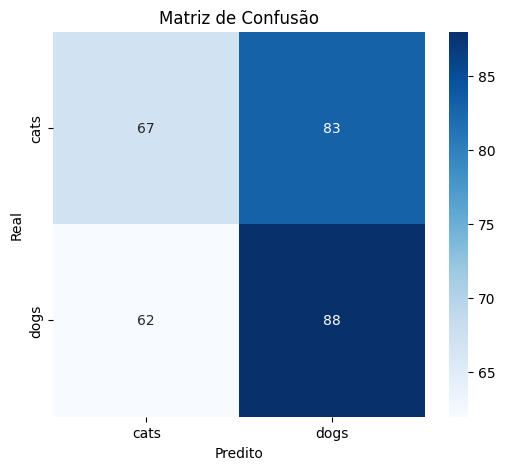


Relatório de Classificação Detalhado:
              precision    recall  f1-score   support

        cats       0.52      0.45      0.48       150
        dogs       0.51      0.59      0.55       150

    accuracy                           0.52       300
   macro avg       0.52      0.52      0.51       300
weighted avg       0.52      0.52      0.51       300



In [ ]:
# 1. Importar as bibliotecas necessárias para a Matriz de Confusão e Métricas
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Definir manualmente as classes caso o kernel tenha sido reiniciado
class_names = ['cats', 'dogs']

# Garantir que as listas globais sejam declaradas
globals().setdefault('reais_lista', [])
globals().setdefault('previstos_lista', [])

# 2. Se as listas estiverem vazias, gerar as previsões automaticamente
if len(reais_lista) == 0 or len(previstos_lista) == 0:
    print("As listas de previsões estavam vazias. Gerando previsões...")

    # Recriar as listas localmente
    imagens_lista = []
    reais_lista = []
    previstos_lista = []
    probabilidades_lista = []

    for imagens, labels in test_ds:
        probabilidades = melhor_modelo.predict(imagens, verbose=0).flatten()
        previsoes = (probabilidades >= 0.5).astype("int32")

        imagens_lista.extend(imagens.numpy())
        reais_lista.extend(labels.numpy())
        previstos_lista.extend(previsoes)
        probabilidades_lista.extend(probabilidades)

    # Salvar de volta no escopo global para que outras células funcionem
    globals()['imagens_lista'] = imagens_lista
    globals()['reais_lista'] = reais_lista
    globals()['previstos_lista'] = previstos_lista
    globals()['probabilidades_lista'] = probabilidades_lista
    print("Previsões geradas com sucesso!")

# 3. Gerar a Matriz de Confusão
cm = confusion_matrix(reais_lista, previstos_lista)

# 4. Plotar a matriz de forma visual amigável
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.ylabel("Real")
plt.xlabel("Predito")
plt.title("Matriz de Confusão")
plt.show()

# 5. Mostrar relatório de métricas usando as variáveis corretas
print("\nRelatório de Classificação Detalhado:")
print(classification_report(reais_lista, previstos_lista, target_names=class_names))

In [ ]:
# ============================================================
# FIM DA PIPELINE
# ============================================================
#
# RESUMO:
#
# 1. Upload do ZIP
# 2. Descompactação
# 3. Identificação de gatos e cachorros
# 4. Separação:
#       70% treino
#       15% validação
#       15% teste
# 5. Carregamento das imagens
# 6. Criação da CNN
# 7. Treinamento
# 8. Checkpoint pelo menor val_loss
# 9. Gráficos de loss e acurácia
# 10. Carregamento do melhor modelo
# 11. Avaliação no conjunto de teste
# 12. Exibição de 5 acertos
# 13. Exibição de 5 erros
# ============================================================
